In [6]:
import os
import platform
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import chisquare, binomtest, norm

SAMPLE_SIZE = 1024 * 1024
OUTPUT_DIR = Path("random_data")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Operating system:", platform.system())
print("Sample size:", f"{SAMPLE_SIZE:,} bytes")
print("Output directory:", OUTPUT_DIR.resolve())


Operating system: Linux
Sample size: 1,048,576 bytes
Output directory: /home/mnit/2024ucp1903/random_data


In [7]:
if platform.system() == "Linux":
    output_file = OUTPUT_DIR / "urandom.bin"

    with open("/dev/urandom", "rb") as source:
        data = source.read(SAMPLE_SIZE)

    if len(data) != SAMPLE_SIZE:
        raise IOError("Incorrect number of bytes generated.")

    output_file.write_bytes(data)

    print("Generated:", len(data), "bytes")
    print("File:", output_file.resolve())
else:
    print("Run this cell on Linux to generate /dev/urandom data.")


Generated: 1048576 bytes
File: /home/mnit/2024ucp1903/random_data/urandom.bin


In [8]:
openssl_file = OUTPUT_DIR / "openssl.bin"

if platform.system() == "Linux":
    result = subprocess.run(
        ["openssl", "rand", "-out", str(openssl_file), str(SAMPLE_SIZE)],
        capture_output=True,
        text=True
    )

    if result.returncode != 0:
        raise RuntimeError(result.stderr)

    if openssl_file.stat().st_size != SAMPLE_SIZE:
        raise IOError("Incorrect OpenSSL output size.")

    print("Generated:", openssl_file.stat().st_size, "bytes")
    print("OpenSSL version:", subprocess.check_output(
        ["openssl", "version"], text=True
    ).strip())
else:
    print("Run this cell on Linux to generate the OpenSSL dataset.")


Generated: 1048576 bytes
OpenSSL version: OpenSSL 3.0.2 15 Mar 2022 (Library: OpenSSL 3.0.2 15 Mar 2022)


In [9]:
import ctypes
from ctypes import wintypes

if platform.system() == "Windows":
    windows_file = OUTPUT_DIR / "windows_cng.bin"

    bcrypt = ctypes.WinDLL("bcrypt")

    bcrypt.BCryptGenRandom.argtypes = [
        wintypes.HANDLE,
        ctypes.POINTER(ctypes.c_ubyte),
        wintypes.ULONG,
        wintypes.ULONG
    ]

    bcrypt.BCryptGenRandom.restype = wintypes.LONG

    buffer = (ctypes.c_ubyte * SAMPLE_SIZE)()

    status = bcrypt.BCryptGenRandom(
        None,
        buffer,
        SAMPLE_SIZE,
        0x00000002
    )

    if status != 0:
        raise OSError(f"BCryptGenRandom failed: 0x{status & 0xFFFFFFFF:08X}")

    windows_file.write_bytes(bytes(buffer))

    print("Generated:", windows_file.stat().st_size, "bytes")
    print("File:", windows_file.resolve())
else:
    print("Not running on Windows. Copy the Windows-generated file here.")


Not running on Windows. Copy the Windows-generated file here.


In [11]:
file_paths = {
    "Linux /dev/urandom": OUTPUT_DIR / "urandom.bin",
    "OpenSSL rand": OUTPUT_DIR / "openssl.bin",
    "Windows CNG": OUTPUT_DIR / "windows_random.bin"
}

for name, path in file_paths.items():
    if path.exists():
        print(f"{name}: {path.stat().st_size:,} bytes")
    else:
        print(f"{name}: MISSING")



Linux /dev/urandom: 1,048,576 bytes
OpenSSL rand: 1,048,576 bytes
Windows CNG: 1,048,576 bytes


In [12]:
missing_files = [
    str(path) for path in file_paths.values()
    if not path.exists()
]

if missing_files:
    raise FileNotFoundError(
        "Missing datasets: " + ", ".join(missing_files)
    )

datasets = {
    name: np.frombuffer(path.read_bytes(), dtype=np.uint8).copy()
    for name, path in file_paths.items()
}

for name, data in datasets.items():
    if len(data) < SAMPLE_SIZE:
        raise ValueError(f"{name} contains fewer than 1 MiB.")

print("All datasets loaded successfully.")


All datasets loaded successfully.


In [13]:
dataset_info = pd.DataFrame([
    {
        "Generator": name,
        "Bytes": len(data),
        "Size (MiB)": len(data) / (1024 * 1024),
        "Unique Byte Values": len(np.unique(data))
    }
    for name, data in datasets.items()
])

display(dataset_info)


,Generator,Bytes,Size (MiB),Unique Byte Values
0,Linux /dev/urandom,1048576,1.0,256
1,OpenSSL rand,1048576,1.0,256
2,Windows CNG,1048576,1.0,256


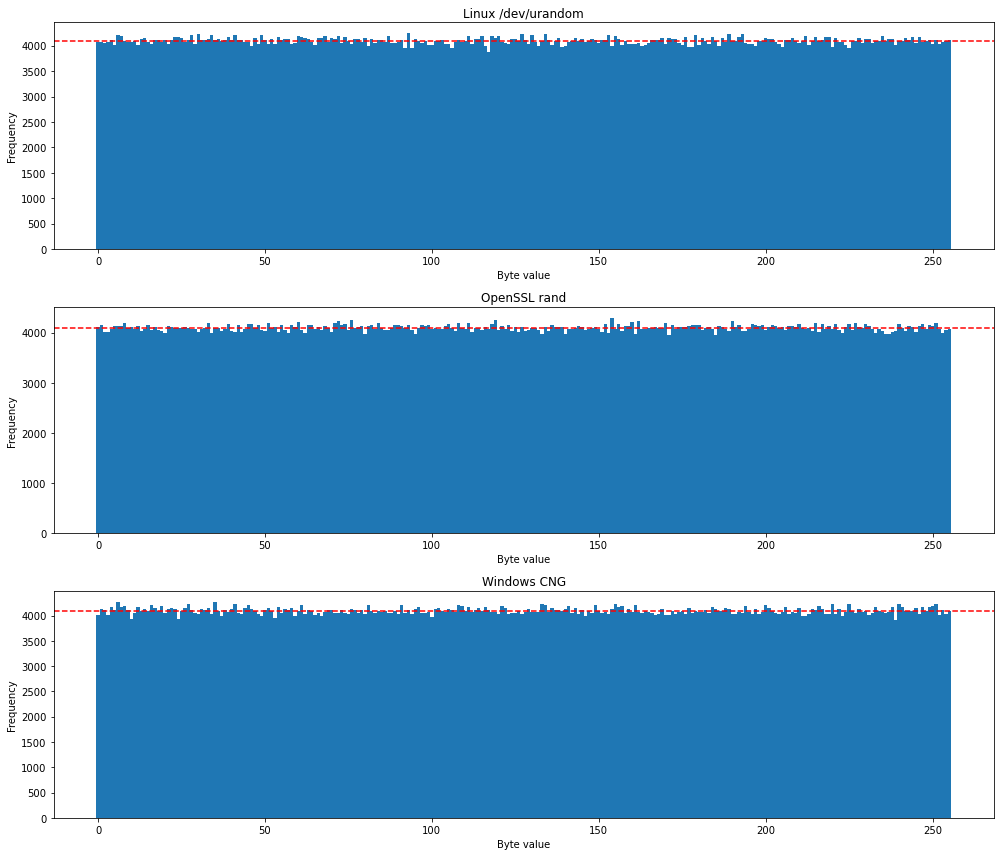

In [14]:
fig, axes = plt.subplots(3, 1, figsize=(14, 12))

for ax, (name, data) in zip(axes, datasets.items()):
    counts = np.bincount(data, minlength=256)

    ax.bar(np.arange(256), counts, width=1.0)
    ax.axhline(len(data) / 256, color="red", linestyle="--")
    ax.set_title(name)
    ax.set_xlabel("Byte value")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()


In [15]:
chi_results = []

for name, data in datasets.items():
    observed = np.bincount(data, minlength=256)
    expected = np.full(256, len(data) / 256)

    statistic, p_value = chisquare(observed, f_exp=expected)

    chi_results.append({
        "Generator": name,
        "Chi-Square Statistic": statistic,
        "Degrees of Freedom": 255,
        "P-Value": p_value,
        "Conclusion": (
            "Reject uniformity"
            if p_value < 0.05
            else "Do not reject uniformity"
        )
    })

chi_df = pd.DataFrame(chi_results)
display(chi_df)


,Generator,Chi-Square Statistic,Degrees of Freedom,P-Value,Conclusion
0,Linux /dev/urandom,244.347656,255,0.673211,Do not reject uniformity
1,OpenSSL rand,224.555664,255,0.915588,Do not reject uniformity
2,Windows CNG,255.983887,255,0.470892,Do not reject uniformity


In [16]:
bit_results = []

for name, data in datasets.items():
    bits = np.unpackbits(data)
    ones = int(bits.sum())
    zeros = len(bits) - ones

    bit_results.append({
        "Generator": name,
        "Total Bits": len(bits),
        "Zeros": zeros,
        "Ones": ones,
        "Zero Percentage": zeros / len(bits) * 100,
        "One Percentage": ones / len(bits) * 100
    })

bit_df = pd.DataFrame(bit_results)
display(bit_df)


,Generator,Total Bits,Zeros,Ones,Zero Percentage,One Percentage
0,Linux /dev/urandom,8388608,4193415,4195193,49.989402,50.010598
1,OpenSSL rand,8388608,4194726,4193882,50.005031,49.994969
2,Windows CNG,8388608,4195376,4193232,50.012779,49.987221


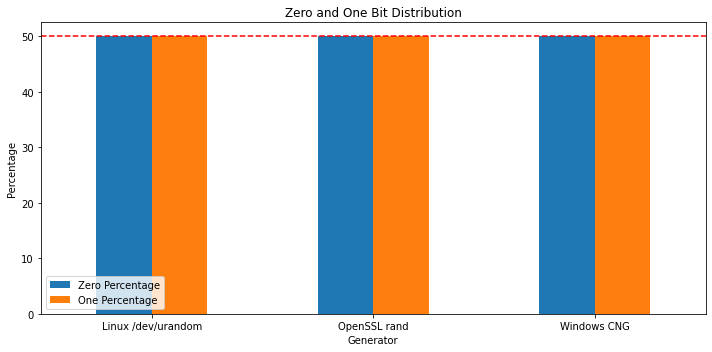

In [17]:
plot_df = bit_df.set_index("Generator")[["Zero Percentage", "One Percentage"]]

plot_df.plot(kind="bar", figsize=(10, 5))
plt.axhline(50, color="red", linestyle="--")
plt.ylabel("Percentage")
plt.title("Zero and One Bit Distribution")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [18]:
monobit_results = []

for name, data in datasets.items():
    bits = np.unpackbits(data)
    ones = int(bits.sum())

    result = binomtest(
        ones,
        n=len(bits),
        p=0.5,
        alternative="two-sided"
    )

    monobit_results.append({
        "Generator": name,
        "Ones": ones,
        "Total Bits": len(bits),
        "One-Bit Percentage": ones / len(bits) * 100,
        "P-Value": result.pvalue,
        "Conclusion": (
            "Reject unbiased-bit model"
            if result.pvalue < 0.05
            else "Do not reject unbiased-bit model"
        )
    })

monobit_df = pd.DataFrame(monobit_results)
display(monobit_df)


,Generator,Ones,Total Bits,One-Bit Percentage,P-Value,Conclusion
0,Linux /dev/urandom,4195193,8388608,50.010598,0.539520,Do not reject unbiased-bit model
1,OpenSSL rand,4193882,8388608,49.994969,0.771005,Do not reject unbiased-bit model
2,Windows CNG,4193232,8388608,49.987221,0.459356,Do not reject unbiased-bit model


In [19]:
pattern_results = []

for name, data in datasets.items():
    byte_counts = np.bincount(data, minlength=256)

    words = (
        data[:-1].astype(np.uint16) * 256
        + data[1:].astype(np.uint16)
    )

    word_counts = np.bincount(words, minlength=65536)

    pattern_results.append({
        "Generator": name,
        "Repeated Byte Occurrences": int(np.maximum(byte_counts - 1, 0).sum()),
        "Distinct Byte Values": int(np.count_nonzero(byte_counts)),
        "Distinct 16-Bit Words": int(np.count_nonzero(word_counts)),
        "Repeated 16-Bit Word Occurrences": int(np.maximum(word_counts - 1, 0).sum())
    })

pattern_df = pd.DataFrame(pattern_results)
display(pattern_df)


,Generator,Repeated Byte Occurrences,Distinct Byte Values,Distinct 16-Bit Words,Repeated 16-Bit Word Occurrences
0,Linux /dev/urandom,1048320,256,65536,983039
1,OpenSSL rand,1048320,256,65536,983039
2,Windows CNG,1048320,256,65536,983039


In [20]:
correlation_results = []

for name, data in datasets.items():
    bits = np.unpackbits(data)

    byte_corr = np.corrcoef(
        data[:-1].astype(np.float64),
        data[1:].astype(np.float64)
    )[0, 1]

    bit_corr = np.corrcoef(
        bits[:-1].astype(np.float64),
        bits[1:].astype(np.float64)
    )[0, 1]

    correlation_results.append({
        "Generator": name,
        "Byte Lag-1 Correlation": byte_corr,
        "Bit Lag-1 Correlation": bit_corr
    })

correlation_df = pd.DataFrame(correlation_results)
display(correlation_df)


,Generator,Byte Lag-1 Correlation,Bit Lag-1 Correlation
0,Linux /dev/urandom,0.000195,0.000489
1,OpenSSL rand,0.000369,-0.000083
2,Windows CNG,0.000755,0.000430


In [21]:
def runs_test(bits):
    bits = np.asarray(bits, dtype=np.uint8)

    n0 = int(np.count_nonzero(bits == 0))
    n1 = int(np.count_nonzero(bits == 1))
    n = n0 + n1

    if n0 == 0 or n1 == 0 or n < 2:
        return np.nan, np.nan, np.nan, np.nan

    runs = 1 + int(np.count_nonzero(bits[1:] != bits[:-1]))

    expected = 1 + (2 * n0 * n1) / n

    variance = (
        2 * n0 * n1 * (2 * n0 * n1 - n)
        / (n**2 * (n - 1))
    )

    if variance <= 0:
        return runs, expected, np.nan, np.nan

    z_score = (runs - expected) / np.sqrt(variance)
    p_value = 2 * norm.sf(abs(z_score))

    return runs, expected, z_score, p_value


runs_results = []

for name, data in datasets.items():
    bits = np.unpackbits(data)
    runs, expected, z_score, p_value = runs_test(bits)

    runs_results.append({
        "Generator": name,
        "Observed Runs": runs,
        "Expected Runs": expected,
        "Z-Score": z_score,
        "P-Value": p_value,
        "Conclusion": (
            "Reject runs-test null hypothesis"
            if not np.isnan(p_value) and p_value < 0.05
            else "Do not reject runs-test null hypothesis"
            if not np.isnan(p_value)
            else "Test undefined"
        )
    })

runs_df = pd.DataFrame(runs_results)
display(runs_df)


,Generator,Observed Runs,Expected Runs,Z-Score,P-Value,Conclusion
0,Linux /dev/urandom,4192252,4.194305e+06,-1.417536,0.156326,Do not reject runs-test null hypothesis
1,OpenSSL rand,4194651,4.194305e+06,0.238954,0.811141,Do not reject runs-test null hypothesis
2,Windows CNG,4192501,4.194305e+06,-1.245534,0.212935,Do not reject runs-test null hypothesis


In [22]:
summary_df = (
    dataset_info
    .merge(
        chi_df[["Generator", "Chi-Square Statistic", "P-Value"]]
        .rename(columns={"P-Value": "Byte Chi-Square P-Value"}),
        on="Generator"
    )
    .merge(
        bit_df[["Generator", "Zero Percentage", "One Percentage"]],
        on="Generator"
    )
    .merge(
        monobit_df[["Generator", "P-Value"]]
        .rename(columns={"P-Value": "Monobit P-Value"}),
        on="Generator"
    )
    .merge(pattern_df, on="Generator")
    .merge(correlation_df, on="Generator")
    .merge(
        runs_df[["Generator", "Observed Runs", "Expected Runs", "Runs-Test P-Value"]]
        if "Runs-Test P-Value" in runs_df.columns
        else runs_df[["Generator", "Observed Runs", "Expected Runs", "P-Value"]]
        .rename(columns={"P-Value": "Runs-Test P-Value"}),
        on="Generator"
    )
)

display(summary_df)


,Generator,Bytes,Size (MiB),Unique Byte Values,Chi-Square Statistic,Byte Chi-Square P-Value,Zero Percentage,One Percentage,Monobit P-Value,Repeated Byte Occurrences,Distinct Byte Values,Distinct 16-Bit Words,Repeated 16-Bit Word Occurrences,Byte Lag-1 Correlation,Bit Lag-1 Correlation,Observed Runs,Expected Runs,Runs-Test P-Value
0,Linux /dev/urandom,1048576,1.0,256,244.347656,0.673211,49.989402,50.010598,0.539520,1048320,256,65536,983039,0.000195,0.000489,4192252,4.194305e+06,0.156326
1,OpenSSL rand,1048576,1.0,256,224.555664,0.915588,50.005031,49.994969,0.771005,1048320,256,65536,983039,0.000369,-0.000083,4194651,4.194305e+06,0.811141
2,Windows CNG,1048576,1.0,256,255.983887,0.470892,50.012779,49.987221,0.459356,1048320,256,65536,983039,0.000755,0.000430,4192501,4.194305e+06,0.212935


In [23]:
OUTPUT_DIR.mkdir(exist_ok=True)

chi_df.to_csv(OUTPUT_DIR / "chi_square_results.csv", index=False)
bit_df.to_csv(OUTPUT_DIR / "bit_distribution_results.csv", index=False)
monobit_df.to_csv(OUTPUT_DIR / "monobit_results.csv", index=False)
pattern_df.to_csv(OUTPUT_DIR / "pattern_results.csv", index=False)
correlation_df.to_csv(OUTPUT_DIR / "correlation_results.csv", index=False)
runs_df.to_csv(OUTPUT_DIR / "runs_test_results.csv", index=False)
summary_df.to_csv(OUTPUT_DIR / "final_comparison.csv", index=False)

print("All result tables saved to:", OUTPUT_DIR.resolve())


All result tables saved to: /home/mnit/2024ucp1903/random_data


In [24]:
for name in datasets:
    chi_p = chi_df.loc[
        chi_df["Generator"] == name, "P-Value"
    ].iloc[0]

    monobit_p = monobit_df.loc[
        monobit_df["Generator"] == name, "P-Value"
    ].iloc[0]

    runs_p = runs_df.loc[
        runs_df["Generator"] == name, "P-Value"
    ].iloc[0]

    print(f"\n{name}")
    print("-" * len(name))

    print(
        "Byte-frequency test:",
        "reject uniformity" if chi_p < 0.05 else "do not reject uniformity",
        f"(p = {chi_p:.6g})"
    )

    print(
        "Monobit test:",
        "reject unbiased-bit model" if monobit_p < 0.05 else "do not reject unbiased-bit model",
        f"(p = {monobit_p:.6g})"
    )

    if pd.notna(runs_p):
        print(
            "Runs test:",
            "reject null hypothesis" if runs_p < 0.05 else "do not reject null hypothesis",
            f"(p = {runs_p:.6g})"
        )



Linux /dev/urandom
------------------
Byte-frequency test: do not reject uniformity (p = 0.673211)
Monobit test: do not reject unbiased-bit model (p = 0.53952)
Runs test: do not reject null hypothesis (p = 0.156326)

OpenSSL rand
------------
Byte-frequency test: do not reject uniformity (p = 0.915588)
Monobit test: do not reject unbiased-bit model (p = 0.771005)
Runs test: do not reject null hypothesis (p = 0.811141)

Windows CNG
-----------
Byte-frequency test: do not reject uniformity (p = 0.470892)
Monobit test: do not reject unbiased-bit model (p = 0.459356)
Runs test: do not reject null hypothesis (p = 0.212935)


In [25]:
print("""
CONCLUSION

This experiment compared random data generated by Linux /dev/urandom,
OpenSSL rand, and Windows CNG.

The datasets were examined using byte-frequency distributions, bit
frequencies, repeated-pattern measurements, serial correlations,
the chi-square goodness-of-fit test, the monobit test, and the runs test.

The statistical results describe selected properties of the observed
outputs. Failure to reject a statistical null hypothesis does not prove
that a generator is cryptographically secure.

Cryptographic security also depends on secure initialization, internal
state protection, implementation correctness, and resistance to prediction
and state-recovery attacks.

The final comparison should be based on the measured results in the tables
above. No generator should be declared cryptographically superior solely
because it obtains a larger p-value.
""")



CONCLUSION

This experiment compared random data generated by Linux /dev/urandom,
OpenSSL rand, and Windows CNG.

The datasets were examined using byte-frequency distributions, bit
frequencies, repeated-pattern measurements, serial correlations,
the chi-square goodness-of-fit test, the monobit test, and the runs test.

The statistical results describe selected properties of the observed
outputs. Failure to reject a statistical null hypothesis does not prove
that a generator is cryptographically secure.

Cryptographic security also depends on secure initialization, internal
state protection, implementation correctness, and resistance to prediction
and state-recovery attacks.

The final comparison should be based on the measured results in the tables
above. No generator should be declared cryptographically superior solely
because it obtains a larger p-value.

